# Re-tuning for the official metric (built: the linear model ships)

**The question:** the models were tuned with per-run TIMSE weights, which over-forecast (+55 km/s), and the
official metric (`training.competition_score`) charges that through RMSE. Which loss weights minimise the
official score?

**The test** (`python -m training.official_retune`): on the six yearly folds, fitted as shipped except for
the weights:
- `shipped − bias`: a per-lead bias post-step;
- `official b`: `weights="official"`, a blend of uniform and the official percentile-TIMSE weights, `models.final_baseline.official_weights`;
- the final baseline's `tail_power`.

Score: the official S_final against the official truth. Keep rule: more than 1% better, winning at least 4 of 6 folds.

1. Scores
2. By fold
3. The RMSE / tail trade-off
4. The eval year (used once, after choosing)
5. Findings

## 1. Scores (S in km/s; geometric means over folds)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import official_retune as rt

df = pd.read_csv(rt.EXPERIMENTS / "official_retune.csv").set_index("fold")
rows = {}
for model in rt.MODELS:
    ref = df[f"shipped | {model} | s_final"]
    for name in rt.VARIANTS:
        s = df[f"{name} | {model} | s_final"]
        rows[(model, name)] = {
            "S_final": s.mean(), "vs shipped": np.exp(np.log(s / ref).mean()) - 1,
            "folds won": int((s < ref).sum()),
            "/ persistence": np.exp(np.log(s / df["persistence | s_final"]).mean()),
            **{k: df[f"{name} | {model} | {k}"].mean() for k in ("rmse", "trmse", "bias")},
            "bias 72h": df[f"{name} | {model} | bias 72h"].mean()}
ref = df[f"{rt.BASELINE_VARIANTS[0]} | s_final"]
for name in rt.BASELINE_VARIANTS:
    s = df[f"{name} | s_final"]
    rows[("final baseline", name.removeprefix("final baseline "))] = {
        "S_final": s.mean(), "vs shipped": np.exp(np.log(s / ref).mean()) - 1,
        "folds won": int((s < ref).sum()),
        "/ persistence": np.exp(np.log(s / df["persistence | s_final"]).mean()),
        **{k: df[f"{name} | {k}"].mean() for k in ("rmse", "trmse", "bias")}}
summary = pd.DataFrame(rows).T
summary["keep"] = (summary["vs shipped"] < -0.01) & (summary["folds won"] >= 4)
with pd.option_context("display.float_format", "{:.3f}".format):
    display(summary)

S_final  vs shipped  folds won  / persistence  \
linear         shipped           93.695       0.000      0.000          0.842   
               shipped - bias    91.525      -0.024      4.000          0.822   
               official b=0      91.148      -0.028      4.000          0.818   
               official b=0.1    89.036      -0.051      5.000          0.799   
               official b=0.25   88.486      -0.059      6.000          0.793   
               official b=0.5    90.238      -0.042      5.000          0.807   
               official b=0.75   94.617       0.005      3.000          0.846   
               official b=1     103.438       0.105      0.000          0.930   
hybrid         shipped           94.002       0.000      0.000          0.843   
               shipped - bias    91.564      -0.023      5.000          0.823   
               official b=0      89.589      -0.046      5.000          0.805   
               official b=0.1    88.497      -0.059      6.000          0.794   
               official b=0.25   89.230      -0.053      6.000          0.799   
               official b=0.5    90.506      -0.041      5.000          0.809   
               official b=0.75   93.481      -0.010      4.000          0.835   
               official b=1      99.304       0.052      0.000          0.887   
final baseline tp=1              99.818       0.000      0.000          0.899   
               tp=0.5            96.209      -0.037      6.000          0.866   
               tp=0.25           96.260      -0.036      6.000          0.866   
               tp=0              97.908      -0.020      3.000          0.881   

                                  rmse   trmse   bias  bias 72h   keep  
linear         shipped          85.848 104.334 56.122    94.649  False  
               shipped - bias   64.442 131.614  6.876     6.128   True  
               official b=0     62.631 134.262  0.887     0.775   True  
               official b=0.1   64.267 124.874  9.921    13.257   True  
               official b=0.25  68.282 116.198 21.728    29.703   True  
               official b=0.5   77.304 106.924 40.622    55.491   True  
               official b=0.75  90.394 100.590 61.760    82.907  False  
               official b=1    111.110  97.712 89.237   117.119  False  
hybrid         shipped          87.094 102.902 57.255    92.406  False  
               shipped - bias   66.300 128.029 11.084    10.746   True  
               official b=0     63.154 128.823  4.843     4.934   True  
               official b=0.1   65.460 121.089 12.589    15.619   True  
               official b=0.25  69.358 115.970 20.787    27.405   True  
               official b=0.5   76.105 108.702 34.098    46.176   True  
               official b=0.75  84.500 104.468 48.083    63.903   True  
               official b=1     97.867 101.704 67.685    87.699  False  
final baseline tp=1             85.717 118.695 52.499       NaN  False  
               tp=0.5           70.900 132.677 24.440       NaN   True  
               tp=0.25          67.217 139.831 12.119       NaN   True  
               tp=0             65.848 147.492  0.646       NaN  False

## 2. By fold (% change in S_final against the shipped model)

fold,2019-10,2020-10,2021-10,2022-10,2023-10,2024-10
linear: shipped - bias,-8.2,-3.1,5.0,1.4,-6.5,-2.3
linear: official b=0,-9.7,-2.9,5.7,0.7,-6.9,-3.0
linear: official b=0.1,-11.7,-5.3,1.6,-1.8,-7.4,-5.5
linear: official b=0.25,-12.9,-6.1,-1.2,-3.4,-7.0,-4.2
linear: official b=0.5,-11.6,-4.2,-2.0,-3.3,-4.5,0.8
linear: official b=0.75,-5.5,1.8,0.4,-0.5,-0.4,7.7
linear: official b=1,10.4,16.1,7.5,5.6,6.0,17.9
hybrid: shipped - bias,-2.9,-2.8,3.0,-1.0,-7.6,-2.5
hybrid: official b=0,-7.7,-4.5,3.8,-3.2,-8.3,-7.0
hybrid: official b=0.1,-9.6,-5.6,-0.1,-4.7,-9.1,-5.7


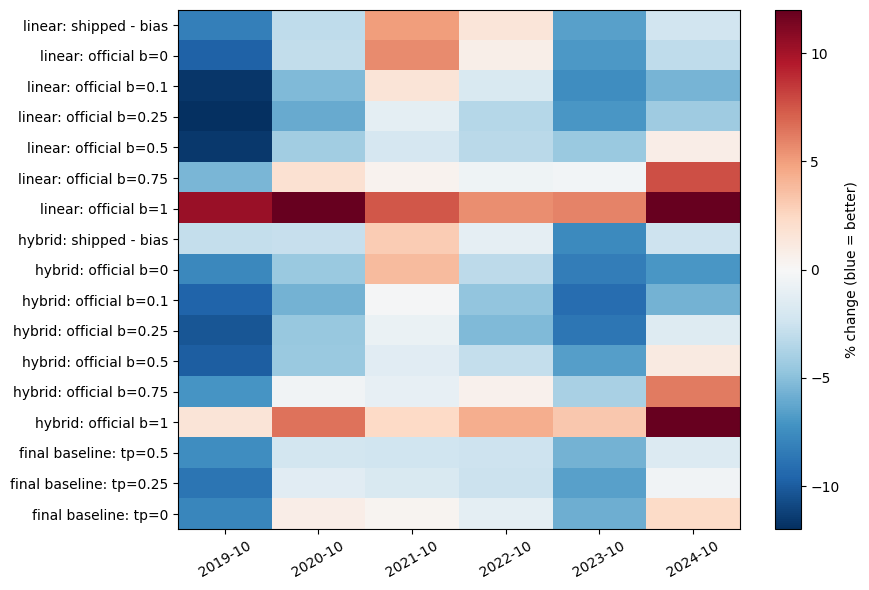

In [2]:
change = {}
for model in rt.MODELS:
    for name in rt.VARIANTS[1:]:
        change[f"{model}: {name}"] = 100 * (df[f"{name} | {model} | s_final"]
                                            / df[f"shipped | {model} | s_final"] - 1)
for name in rt.BASELINE_VARIANTS[1:]:
    change[f"final baseline: {name.removeprefix('final baseline ')}"] = 100 * (
        df[f"{name} | s_final"] / df[f"{rt.BASELINE_VARIANTS[0]} | s_final"] - 1)
change = pd.DataFrame(change)
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(change.T.to_numpy(), cmap="RdBu_r", vmin=-12, vmax=12, aspect="auto")
ax.set_yticks(range(change.shape[1]), change.columns)
ax.set_xticks(range(change.shape[0]), change.index, rotation=30)
plt.colorbar(im, label="% change (blue = better)")
plt.tight_layout()
display(change.T.round(1))

## 3. The RMSE / tail trade-off across blends (mean over folds)

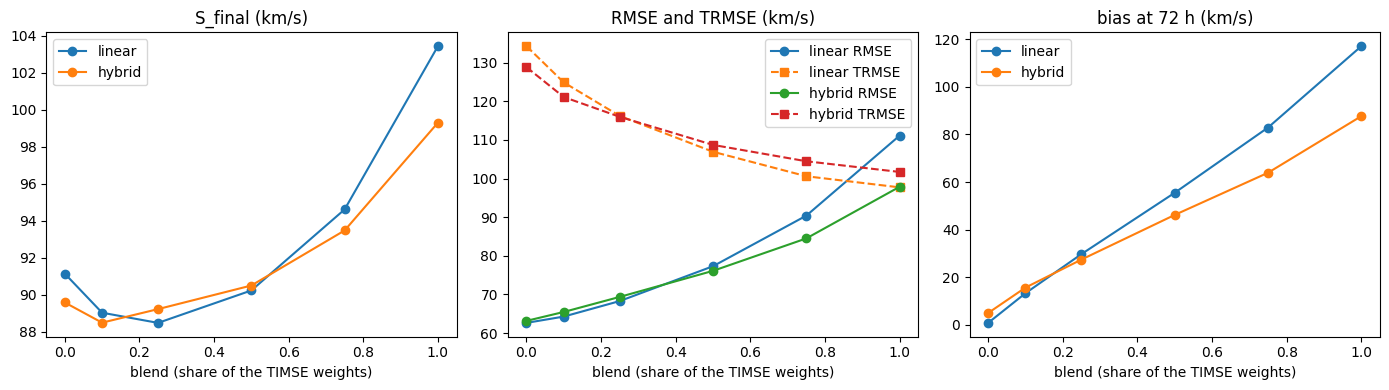

In [3]:
blends = rt.BLENDS
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for model in rt.MODELS:
    def g(k, model=model):
        return [df[f"official b={b:g} | {model} | {k}"].mean() for b in blends]

    axes[0].plot(blends, g("s_final"), "o-", label=model)
    axes[1].plot(blends, g("rmse"), "o-", label=f"{model} RMSE")
    axes[1].plot(blends, g("trmse"), "s--", label=f"{model} TRMSE")
    axes[2].plot(blends, [df[f"official b={b:g} | {model} | bias 72h"].mean() for b in blends],
                 "o-", label=model)
axes[0].set_title("S_final (km/s)")
axes[1].set_title("RMSE and TRMSE (km/s)")
axes[2].set_title("bias at 72 h (km/s)")
for ax in axes:
    ax.set_xlabel("blend (share of the TIMSE weights)")
    ax.legend()
plt.tight_layout()

## 4. The eval year (2025-10 → 2026-10, used once after choosing)

In [4]:
ev = pd.read_csv(rt.EXPERIMENTS / "official_eval_year.csv", index_col=0)
with pd.option_context("display.float_format", "{:.3f}".format):
    display(ev[["s_final", "/ persistence", "rmse", "trmse", "bias", "bias 72h", "s_49_72"]])

,s_final,/ persistence,rmse,trmse,bias,bias 72h,s_49_72
hybrid (shipped),122.697,0.780,97.810,156.892,58.951,105.503,140.669
linear (new),123.733,0.787,87.555,177.399,34.376,49.554,139.434
linear (previous),125.838,0.800,98.204,164.905,58.726,107.179,145.338
final baseline (new),131.587,0.837,87.572,199.517,28.461,48.689,147.687
final baseline (previous),136.773,0.870,107.593,177.077,66.457,107.193,153.955
persistence,157.280,1.000,105.060,238.388,1.254,1.733,184.838
recurrence 27 d,165.122,1.050,115.571,236.610,4.904,3.072,172.717


## 5. Findings

- **Re-tuning the loss for the official metric is worth about 6%.**
  - The linear model at blend 0.25 is 5.9% better than shipped (6 of 6 folds), and the hybrid at blend 0.1 the same.
  - The final baseline at tail_power 0.5 is 3.7% better (6 of 6).
- **The trade-off is between RMSE and the tail term.** More TIMSE weight lowers TRMSE but raises the bias and RMSE (section 3), and the best blend keeps a modest upward lean.
- **Removing the bias alone recovers 2.4%.** The rest comes from refitting with the balanced loss.
- **The hybrid and the linear model tie** at their best blends (88.5 km/s). The trees don't clear the 1% / 4-of-6 bar, so the simpler linear model ships.
- **The eval year** (section 4, used once after choosing) confirms the re-tuning: linear −1.7% and final baseline −3.8% against their previous versions. The previously shipped hybrid is 0.8% better there; the year was unusually fast.

**Decision:** built. The linear model (official weights, blend 0.25) is the submitted model from 2026-10-26, and the final baseline uses tail_power 0.5. See `docs/official_retune.md`.